# Danish renewable regimes and electricity prices

## tl;dr
This notebook reruns the cached official-data pilot. The executed findings below are the controlling empirical summary. No causal or operational forecasting interpretation is supported.

## Context & Methods
2023 training and 2024 out-of-time validation, DK1/DK2. Essential course topics: K-means and independently implemented Apriori. Additional method: synchronous seven-day moving-block bootstrap.

### Key Assumptions
Gross consumption is a settlement-derived demand proxy; solar self-consumption is estimated. Rules and all transformations are chosen on 2023 only. High price means above the fixed area-specific 2023 95th percentile. Units: MWh per hourly interval and EUR/MWh. See README for uncertainty, missing-value and model-selection details.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'scripts/run_pilot.py').exists(), 'Open within this repository'
sys.path.insert(0, str(ROOT / 'src'))
RESULTS = ROOT / 'results'

## Data
Source: Energinet Energi Data Service, CC BY 4.0. [Production metadata](https://api.energidataservice.dk/meta/dataset/ProductionConsumptionSettlement), [price metadata](https://api.energidataservice.dk/meta/dataset/Elspotprices). Exact cached URL/parameter/download-time envelopes are in data/cache. Local year membership and DST are validated from UTC keys.

### Reproduce from cached responses
Run the live CLI once if the cache is unavailable. No network requests are made by this cell.

In [2]:
execution = subprocess.run([sys.executable, str(ROOT / 'scripts/run_pilot.py'), '--offline'], cwd=ROOT, capture_output=True, text=True)
if execution.returncode:
    raise RuntimeError(execution.stdout[-3000:] + execution.stderr[-3000:])
print('Cached pipeline completed successfully.')
coverage = pd.read_csv(RESULTS / 'coverage.csv')
display(coverage.groupby(['source', 'area'])[['expected','observed','missing','null_cells']].sum())

Cached pipeline completed successfully.


expected  observed  missing  null_cells
source                          area                                         
Elspotprices                    DK1      17544     17544        0           0
                                DK2      17544     17544        0           0
ProductionConsumptionSettlement DK1      17544     17544        0           0
                                DK2      17544     17544        0           0

## Results
### Event counts and baselines

In [3]:
display(pd.read_csv(RESULTS / 'event_rates.csv'))
display(pd.read_csv(RESULTS / 'k_diagnostics.csv'))
display(pd.read_csv(RESULTS / 'calendar_baseline.csv'))

,year,PriceArea,n,negative_events,high_events,negative_rate,high_rate
0,2023,DK1,8760,281,438,0.032078,0.050000
1,2023,DK2,8760,231,438,0.026370,0.050000
2,2024,DK1,8784,375,226,0.042691,0.025729
3,2024,DK2,8784,275,256,0.031307,0.029144


,k,silhouette,davies_bouldin,min_cluster_fraction,seed_stability_ari
0,3,0.346448,1.075620,0.172432,0.997752
1,4,0.352605,0.958679,0.151313,0.999823
2,5,0.338406,0.943220,0.140753,0.991382
3,6,0.336023,0.995166,0.052740,0.973580
4,7,0.305259,1.028282,0.052055,0.989568


,event,model,n,fallback_rows,brier
0,negative_price,calendar,17568,0,0.033824
1,negative_price,calendar_plus_cluster,17568,0,0.032069
2,high_price,calendar,17568,0,0.027934
3,high_price,calendar_plus_cluster,17568,0,0.028619


### A preselected validation week
The first seven days are fixed before inspecting prices. UTC axes avoid repeated local DST hours.

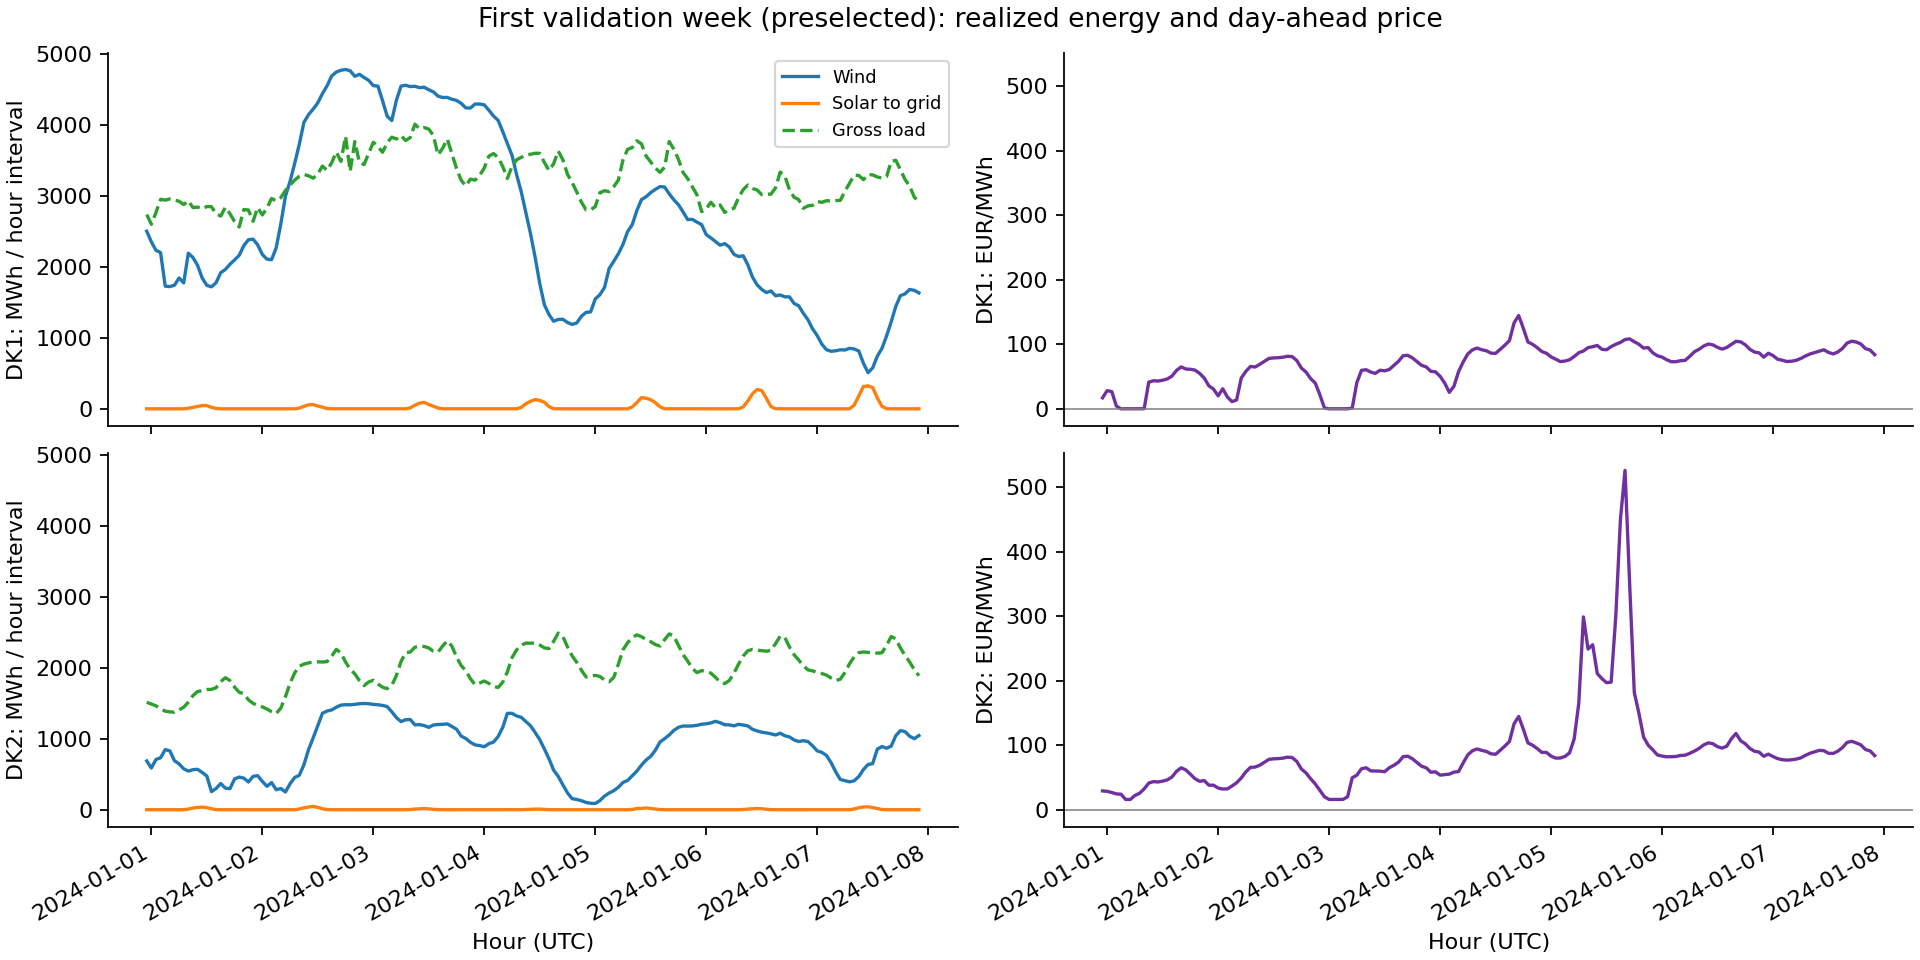

In [4]:
display(Image(filename=str(RESULTS / 'figures/week.png')))

### Energy regimes
Cells require more than 20 observed hours; empty cells are not zeros.

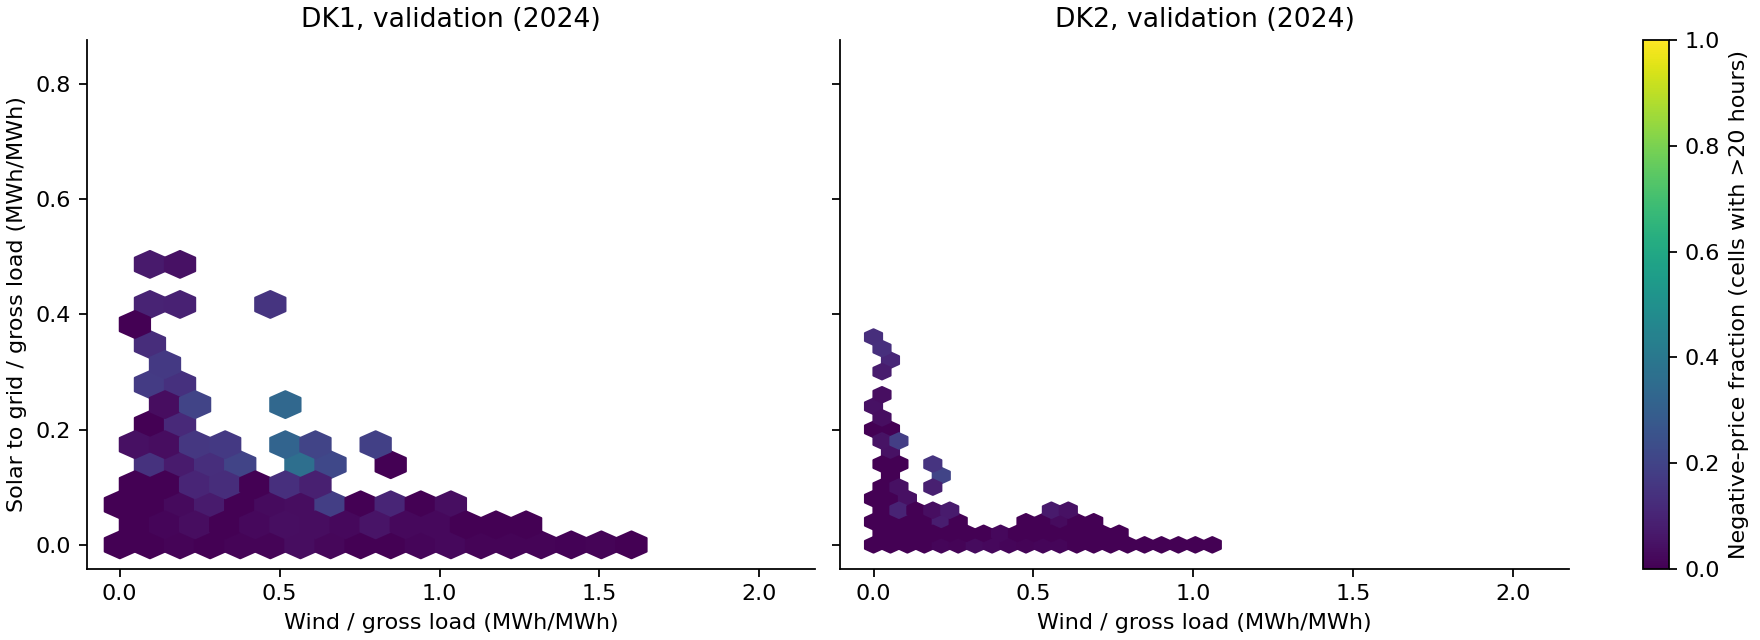

In [5]:
display(Image(filename=str(RESULTS / 'figures/regimes.png')))

### Cluster interpretation
Centroids use unscaled dimensionless physical ratios; cluster labels have no ordinal meaning.

,cluster,wind_to_load,solar_to_load,load_index
0,0,1.018641,0.027676,1.014205
1,1,0.298332,0.017953,0.809110
2,2,0.313100,0.375675,1.015806
3,3,0.373742,0.043765,1.173909


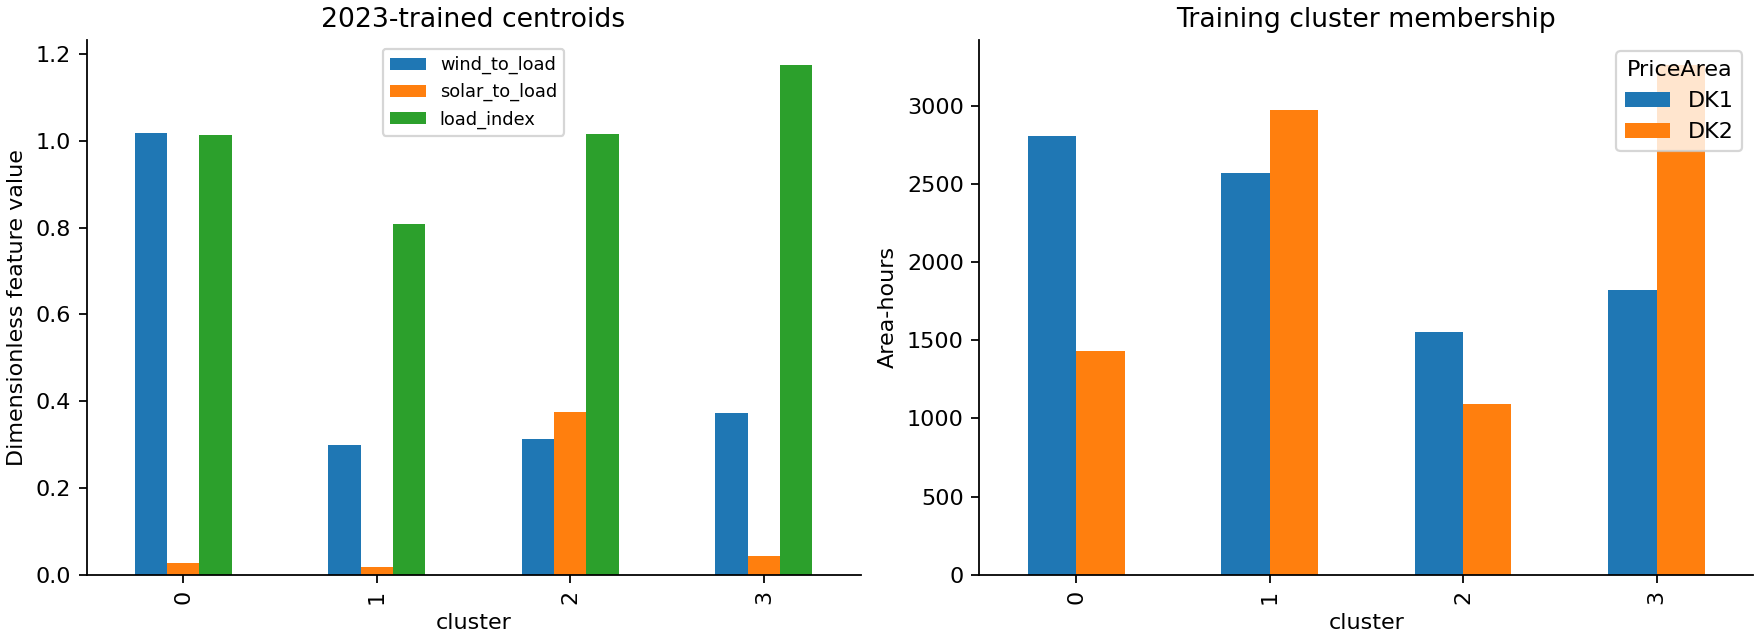

In [6]:
display(pd.read_csv(RESULTS / 'cluster_centers.csv'))
display(Image(filename=str(RESULTS / 'figures/clusters.png')))

### Frozen rules and uncertainty
Lift uses the matching area and year baseline. Intervals are exploratory 95% seven-day moving-block bootstrap intervals and do not correct selection bias.

,event,antecedent,train_n,train_events,train_lift,test_n,test_events,test_lift,ci_low,ci_high,test_small_sample
0,negative_price,area=DK1 & cluster=C0 & season=summer,383.0,54.0,4.395343,507.0,21.0,0.970225,0.355220,1.923605,False
1,negative_price,area=DK2 & cluster=C1 & season=autumn,763.0,60.0,2.982077,708.0,17.0,0.766965,0.089797,1.716104,True
2,high_price,area=DK1 & cluster=C3 & season=winter,824.0,204.0,4.951456,919.0,74.0,3.129681,0.000000,5.539711,False
3,high_price,area=DK2 & cluster=C3 & season=winter,1375.0,252.0,3.665455,1590.0,99.0,2.136439,0.617532,3.504914,False


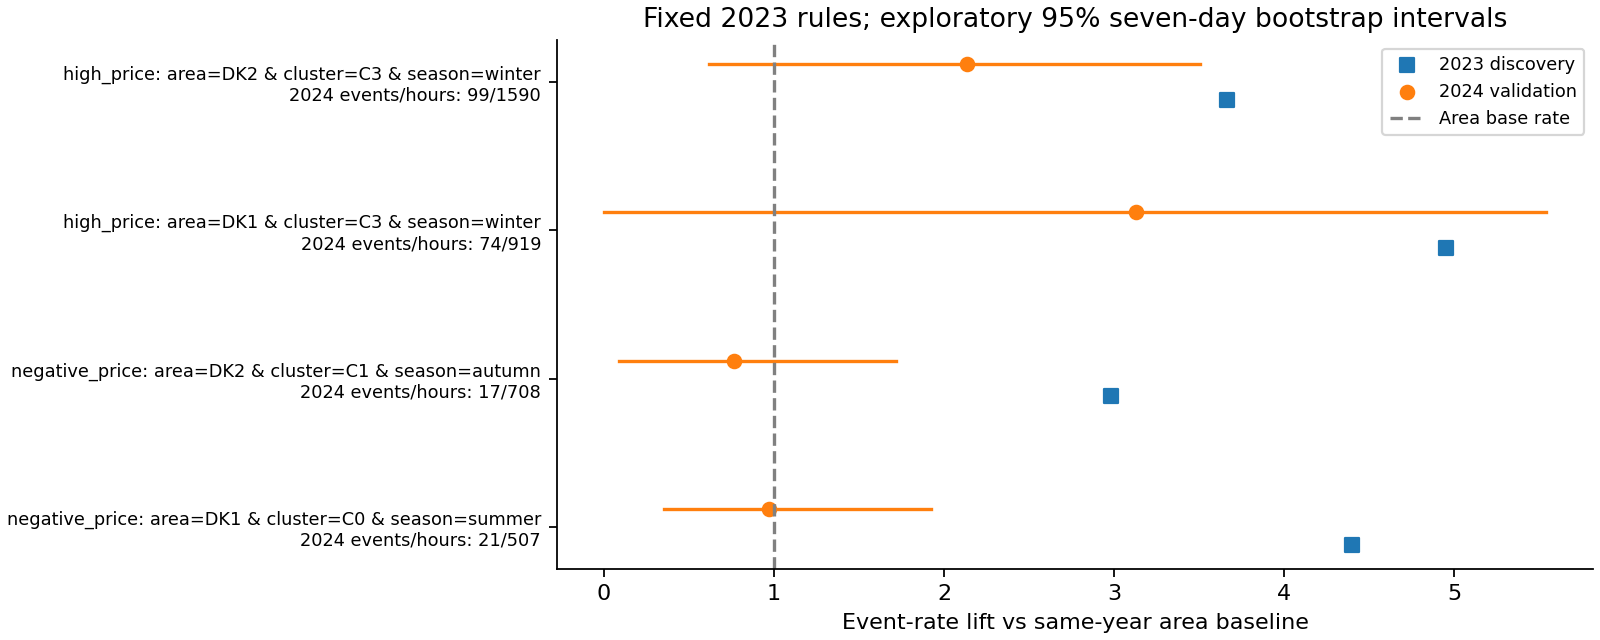

In [7]:
rules = pd.read_csv(RESULTS / 'selected_rules.csv')
display(rules[['event','antecedent','train_n','train_events','train_lift','test_n','test_events','test_lift','ci_low','ci_high','test_small_sample']])
if (RESULTS / 'figures/rules.png').exists():
    display(Image(filename=str(RESULTS / 'figures/rules.png')))

### Estimated solar self-consumption sensitivity
These scores keep the primary frozen centroids and rule definitions while changing the solar feature. The separate sensitivity folder also contains a full training-only refit.

In [8]:
display(pd.read_csv(RESULTS / 'sensitivity_comparison.csv'))

,event,antecedent,n,events,support,joint_support,confidence,base_rate,lift,small_sample,primary_lift_same_rows,lift_difference
0,negative_price,area=DK1 & cluster=C0 & season=summer,489.0,18.0,0.027835,0.001025,0.036810,0.042691,0.862233,True,0.970225,-0.107992
1,negative_price,area=DK2 & cluster=C1 & season=autumn,703.0,17.0,0.040016,0.000968,0.024182,0.031307,0.772420,True,0.766965,0.005455
2,high_price,area=DK1 & cluster=C3 & season=winter,917.0,74.0,0.052197,0.004212,0.080698,0.025729,3.136507,False,3.129681,0.006826
3,high_price,area=DK2 & cluster=C3 & season=winter,1587.0,99.0,0.090335,0.005635,0.062382,0.029144,2.140477,False,2.136439,0.004039


## Takeaways
The following report is generated from this execution, including whether the energy grouping improves over the calendar-only baseline. Inspect exact event denominators before interpreting negative-price enrichment.

In [9]:
display(Markdown((RESULTS / 'pilot_findings.md').read_text(encoding='utf-8')))

# Pilot findings

Scope: complete requested source coverage.
Historical associations in realized settlement data; not causal or day-ahead forecasts.

## Event denominators
| year | PriceArea | n | negative_events | high_events | negative_rate | high_rate |
| --- | --- | --- | --- | --- | --- | --- |
| 2023 | DK1 | 8760 | 281 | 438 | 0.0321 | 0.0500 |
| 2023 | DK2 | 8760 | 231 | 438 | 0.0264 | 0.0500 |
| 2024 | DK1 | 8784 | 375 | 226 | 0.0427 | 0.0257 |
| 2024 | DK2 | 8784 | 275 | 256 | 0.0313 | 0.0291 |

## Frozen rules
| event | antecedent | 2023 events/hours | train_lift | 2024 events/hours | test_lift | 2024 interval | test_small_sample |
| --- | --- | --- | --- | --- | --- | --- | --- |
| negative_price | area=DK1 & cluster=C0 & season=summer | 54/383 | 4.3953 | 21/507 | 0.9702 | [0.36, 1.92] | False |
| negative_price | area=DK2 & cluster=C1 & season=autumn | 60/763 | 2.9821 | 17/708 | 0.7670 | [0.09, 1.72] | True |
| high_price | area=DK1 & cluster=C3 & season=winter | 204/824 | 4.9515 | 74/919 | 3.1297 | [0.00, 5.54] | False |
| high_price | area=DK2 & cluster=C3 & season=winter | 252/1375 | 3.6655 | 99/1590 | 2.1364 | [0.62, 3.50] | False |

Rules were selected only on 2023, at most one per area and event; exploratory intervals use 400 synchronous seven-day moving-block replicates.
Transfer is assessed by validation lift: >1 indicates enrichment against the matching 2024 area base rate; intervals crossing 1 do not clearly support enrichment.

## Calendar-only comparison
| event | model | n | fallback_rows | brier |
| --- | --- | --- | --- | --- |
| negative_price | calendar | 17568 | 0 | 0.0338 |
| negative_price | calendar_plus_cluster | 17568 | 0 | 0.0321 |
| high_price | calendar | 17568 | 0 | 0.0279 |
| high_price | calendar_plus_cluster | 17568 | 0 | 0.0286 |
Lower holdout Brier score is better. Calendar+cluster uses the same season/time/area groups plus energy cluster; all cell probabilities fit on training only.

high_price: calendar+cluster worsens holdout Brier by 0.000685. This is a descriptive probability baseline, not an operational forecast.
negative_price: calendar+cluster improves holdout Brier by 0.001755. This is a descriptive probability baseline, not an operational forecast.

## Energy regimes (training centroids)
Selected k=4: sampled silhouette 0.353, Davies-Bouldin 0.959, smallest cluster 15.1%, two-seed adjusted Rand agreement 1.000. Silhouette indicates imperfect separation; labels are exploratory summaries.
| cluster | wind_to_load | solar_to_load | load_index |
| --- | --- | --- | --- |
| 0 | 1.0186 | 0.0277 | 1.0142 |
| 1 | 0.2983 | 0.0180 | 0.8091 |
| 2 | 0.3131 | 0.3757 | 1.0158 |
| 3 | 0.3737 | 0.0438 | 1.1739 |
C0: highest wind/load (relative to the other learned centroids).
C1: lowest load index (relative to the other learned centroids).
C2: highest grid-solar/load (relative to the other learned centroids).
C3: highest load index (relative to the other learned centroids).
negative_price, area=DK1 & cluster=C0 & season=summer: point-estimate enrichment does not persist; validation lift 0.97, exploratory interval [0.36, 1.92].
negative_price, area=DK2 & cluster=C1 & season=autumn: point-estimate enrichment does not persist; validation lift 0.77, exploratory interval [0.09, 1.72].
high_price, area=DK1 & cluster=C3 & season=winter: point-estimate enrichment persists; validation lift 3.13, exploratory interval [0.00, 5.54].
high_price, area=DK2 & cluster=C3 & season=winter: point-estimate enrichment persists; validation lift 2.14, exploratory interval [0.62, 3.50].
0/4 selected rules have exploratory intervals entirely above lift 1; point estimates alone do not establish stable enrichment.

Negative-price support: 2 selected rules; small-sample flags apply to 1 (<100 matching hours or <20 matching events in validation). See exact counts above.

## Estimated solar self-consumption sensitivity
| event | antecedent | primary_lift_same_rows | lift | lift_difference | n | events |
| --- | --- | --- | --- | --- | --- | --- |
| negative_price | area=DK1 & cluster=C0 & season=summer | 0.9702 | 0.8622 | -0.1080 | 489.0000 | 18.0000 |
| negative_price | area=DK2 & cluster=C1 & season=autumn | 0.7670 | 0.7724 | 0.0055 | 703.0000 | 17.0000 |
| high_price | area=DK1 & cluster=C3 & season=winter | 3.1297 | 3.1365 | 0.0068 | 917.0000 | 74.0000 |
| high_price | area=DK2 & cluster=C3 & season=winter | 2.1364 | 2.1405 | 0.0040 | 1587.0000 | 99.0000 |
Primary fixed centroids/rules are evaluated with grid solar and total estimated solar on the same available holdout rows. Positive lift_difference means higher enrichment under the estimated total. This is not evidence that the estimate is more accurate.

## Interpretation and limits
Centroids are given in cluster_centers.csv (wind/load, grid-solar/load, area-median load index). Cluster IDs are algorithmic, with no implied ordering.
Gross consumption is a settlement-derived proxy. Grid solar excludes estimated self-consumption. Source metadata warns some reported zeros may represent missing data; zeros are retained as reported, not imputed. This ambiguity cannot be resolved from these sources.
Serial dependence, overlapping rules, training selection and multiple comparisons limit inference. Bootstrap intervals are exploratory and do not correct discovery bias. Repeat with different block lengths before final reporting.
Generation is observed after market clearing. Interconnectors, fuel costs and weather are omitted; no causal interpretation is supported.
Sensitivity results (separately refitted on training only) are in sensitivity/ and sensitivity_comparison.csv; IDs across fits are not equivalent.

## Next iteration
1. Inspect data-quality and solar-sensitivity diagnostics before interpreting rules.
2. Check block-length and rule-selection stability without tuning against 2024.
3. Verify the final submission date on DTU Learn; plan for December 4, 2026 (the assignment also mentions December 6).

Source: Energinet Energi Data Service, CC BY 4.0. Exact cached request envelopes and metadata: data/cache/.
